# Practical No. 05 — Image Generation using Pretrained Stable Diffusion

**Name:** Gayatri Pandharinath Gaikwad

  **Roll No.:** 202502110002
  
  **Class:** TY - CSE(AIML)


## Aim
Implement a pretrained Stable Diffusion model with the Hugging Face **Diffusers** library to generate images from text prompts, and analyse the effect of **(a) prompt design / negative prompts, (b) number of inference steps, (c) guidance scale and (d) sampling method (scheduler)** on image quality.

## Contents
1. Theory — how Stable Diffusion works
2. Setup & loading the pretrained pipeline
3. Identifying the components (text encoder, U-Net, scheduler, VAE)
4. Text-to-image generation (basic)
5. Under the hood — manual denoising loop
6. Prompt engineering & negative prompts
7. Effect of inference steps
8. Effect of guidance scale
9. Effect of sampling method (scheduler)
10. Combined steps × guidance grid and seed variation
11. Result tables, analysis & conclusion


## 1. Theory

**Diffusion models** learn to generate data by reversing a gradual noising process.
* **Forward process:** noise is added to a clean image step by step until it becomes pure Gaussian noise.
* **Reverse process (denoising):** a neural network learns to predict the noise in a noisy input; subtracting the predicted noise step by step turns random noise into an image.

**Stable Diffusion = Latent Diffusion Model.** Instead of denoising full-resolution pixels (512×512×3 ≈ 786k values), it denoises a small **latent** (64×64×4 ≈ 16k values) — about 48× fewer values, so it is much faster and uses less memory.

### Components of the pipeline (SD v1.5)
| Component | Model | Role |
|---|---|---|
| **Tokenizer + Text encoder** | CLIP ViT-L/14 text transformer | Converts the prompt into 77 token embeddings (77×768). This is the *conditioning* signal. |
| **U-Net** | ~860M-parameter UNet2DConditionModel with cross-attention | Predicts the noise in the latent at timestep *t*, conditioned on the text embeddings (cross-attention). |
| **Scheduler (sampler)** | PNDM / DDIM / Euler / DPM++ … | Decides the timesteps and how to use the predicted noise to compute the next, less-noisy latent. |
| **VAE** (AutoencoderKL) | Encoder + Decoder | Encoder: image → latent (used in training / img2img). Decoder: final latent → 512×512 image. |

### Classifier-Free Guidance (CFG)
At every step the U-Net is run twice — once with an *empty* prompt (unconditional) and once with the real prompt (conditional):

`noise = noise_uncond + guidance_scale × (noise_cond − noise_uncond)`

* `guidance_scale = 1` → plain conditional prediction, weak prompt adherence (Diffusers then skips the unconditional pass entirely, so each step is about twice as fast).
* Larger values push the image harder towards the prompt (better adherence) but reduce diversity and, if too large, cause over-saturated / artefact-ridden images.
* A **negative prompt** replaces the empty "unconditional" prompt, so the image is pushed *away* from the negative text.

### Inference steps & schedulers
The model was trained with 1000 noise timesteps. At inference we sample only a subset (e.g. 20–50). More steps → finer integration of the reverse process → usually better detail, but with diminishing returns and linear increase in time. Fast ODE solvers such as DPM++ 2M and UniPC (and also Euler/DDIM) reach good quality in roughly 15–25 steps, whereas the original DDPM sampler needs hundreds of steps.

## 2. Setup & loading the pretrained pipeline

In [1]:
!pip install -q -U diffusers transformers accelerate safetensors scipy matplotlib pandas

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.


In [2]:
import os, time, gc
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

from diffusers import (
    StableDiffusionPipeline,
    PNDMScheduler, DDIMScheduler,
    EulerDiscreteScheduler, EulerAncestralDiscreteScheduler,
    DPMSolverMultistepScheduler, LMSDiscreteScheduler, UniPCMultistepScheduler,
)

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32
print("Device:", device, "| dtype:", dtype)
if device == "cpu":
    print("WARNING: no GPU found. Generation will be extremely slow. Use Runtime > Change runtime type > T4 GPU.")

os.makedirs("outputs", exist_ok=True)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Device: cuda | dtype: torch.float16


In [3]:
MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"   # pretrained SD v1.5 weights on Hugging Face

load_kwargs = dict(torch_dtype=dtype, use_safetensors=True)
if device == "cuda":
    load_kwargs["variant"] = "fp16"          # download the smaller fp16 weights
pipe = StableDiffusionPipeline.from_pretrained(MODEL_ID, **load_kwargs)
pipe = pipe.to(device)
pipe.enable_attention_slicing()          # lowers memory use, helps on free Colab GPUs

DEFAULT_SCHEDULER_CONFIG = pipe.scheduler.config   # keep a copy so we can switch schedulers freely
print("Pipeline loaded:", type(pipe).__name__)

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Pipeline loaded: StableDiffusionPipeline


## 3. Identifying the components of the pipeline
The `StableDiffusionPipeline` object bundles all the sub-models. We print each one with its parameter count.

In [4]:
def n_params_m(model):
    return sum(p.numel() for p in model.parameters()) / 1e6

rows = [
    ("Tokenizer",    type(pipe.tokenizer).__name__,    "-",                         "Splits prompt into tokens (max 77)"),
    ("Text encoder", type(pipe.text_encoder).__name__, f"{n_params_m(pipe.text_encoder):.0f} M", "Prompt -> embeddings (77 x 768), conditioning"),
    ("U-Net",        type(pipe.unet).__name__,         f"{n_params_m(pipe.unet):.0f} M",         "Predicts noise in latent, cross-attends to text"),
    ("VAE",          type(pipe.vae).__name__,          f"{n_params_m(pipe.vae):.0f} M",          "Latent (4x64x64) <-> image (3x512x512)"),
    ("Scheduler",    type(pipe.scheduler).__name__,    "-",                         "Controls timesteps / denoising update rule"),
    ("Safety checker", type(pipe.safety_checker).__name__ if pipe.safety_checker is not None else "None", "-", "Filters NSFW outputs"),
]
display(pd.DataFrame(rows, columns=["Component", "Class", "Parameters", "Role"]))

print("\nU-Net input channels (latent channels):", pipe.unet.config.in_channels)
print("VAE scaling factor:", pipe.vae.config.scaling_factor)
print("VAE downsampling factor:", pipe.vae_scale_factor, "(512 px image -> %d x %d latent)" % (512 // pipe.vae_scale_factor, 512 // pipe.vae_scale_factor))
print("Default scheduler config:", pipe.scheduler.config["_class_name"])

,Component,Class,Parameters,Role
0,Tokenizer,CLIPTokenizer,-,Splits prompt into tokens (max 77)
1,Text encoder,CLIPTextModel,123 M,"Prompt -> embeddings (77 x 768), conditioning"
2,U-Net,UNet2DConditionModel,860 M,"Predicts noise in latent, cross-attends to text"
3,VAE,AutoencoderKL,84 M,Latent (4x64x64) <-> image (3x512x512)
4,Scheduler,PNDMScheduler,-,Controls timesteps / denoising update rule
5,Safety checker,StableDiffusionSafetyChecker,-,Filters NSFW outputs



U-Net input channels (latent channels): 4
VAE scaling factor: 0.18215
VAE downsampling factor: 8 (512 px image -> 64 x 64 latent)
Default scheduler config: PNDMScheduler


### Helper functions
* `generate()` – runs the pipeline with fixed seed so that **only one parameter changes at a time** (fair comparison).
* `show_grid()` – displays and saves a labelled grid of images.
* `clip_score()` – a quantitative prompt-adherence metric: cosine similarity between the CLIP embeddings of the image and the prompt, ×100 (higher = image matches prompt better).

In [5]:
def generate(prompt, negative_prompt=None, steps=30, guidance=7.5, seed=42,
             scheduler_cls=None, size=512):
    """Generate one image. Returns (PIL image, seconds taken)."""
    # always (re)set scheduler so experiments do not leak into each other
    cls = scheduler_cls if scheduler_cls is not None else PNDMScheduler
    pipe.scheduler = cls.from_config(DEFAULT_SCHEDULER_CONFIG)

    gen = torch.Generator(device=device).manual_seed(seed)
    if device == "cuda":
        torch.cuda.synchronize()
    t0 = time.time()
    img = pipe(prompt=prompt, negative_prompt=negative_prompt,
               num_inference_steps=steps, guidance_scale=guidance,
               generator=gen, height=size, width=size).images[0]
    if device == "cuda":
        torch.cuda.synchronize()
    if np.asarray(img).max() == 0:
        print("WARNING: all-black image returned - the safety checker flagged this output. "
              "Try a different seed or a more neutral prompt.")
    return img, time.time() - t0


def show_grid(images, titles, cols=4, size=3.6, suptitle=None, fname=None):
    rows = int(np.ceil(len(images) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * size, rows * (size + 0.5)))
    axes = np.array(axes).reshape(-1)
    for ax in axes:
        ax.axis("off")
    for ax, im, t in zip(axes, images, titles):
        ax.imshow(im)
        ax.set_title(t, fontsize=9)
    if suptitle:
        fig.suptitle(suptitle, fontsize=13, fontweight="bold")
    plt.tight_layout()
    if fname:
        plt.savefig(f"outputs/{fname}.png", dpi=150, bbox_inches="tight")
    plt.show()


from transformers import CLIPModel, CLIPProcessor
clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device).eval()
clip_proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

@torch.no_grad()
def clip_score(image, text):
    inputs = clip_proc(text=[text], images=image, return_tensors="pt",
                       padding=True, truncation=True).to(device)
    return float(clip_model(**inputs).logits_per_image.item())   # = 100 * cosine similarity


def free_mem():
    gc.collect()
    if device == "cuda":
        torch.cuda.empty_cache()


# Warm-up run: the very first GPU call is slower (CUDA kernels / cuDNN initialise),
# which would distort the timing results of the first experiment.
_ = generate("warm up", steps=2, guidance=7.5, seed=0)
print("Warm-up done - timings below are now reliable.")

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

...

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

  0%|          | 0/2 [00:00<?, ?it/s]

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


Warm-up done - timings below are now reliable.


## 4. Basic text-to-image generation
Default settings: 30 steps, guidance scale 7.5, seed 42, default scheduler of the model (PNDM).

  0%|          | 0/30 [00:00<?, ?it/s]

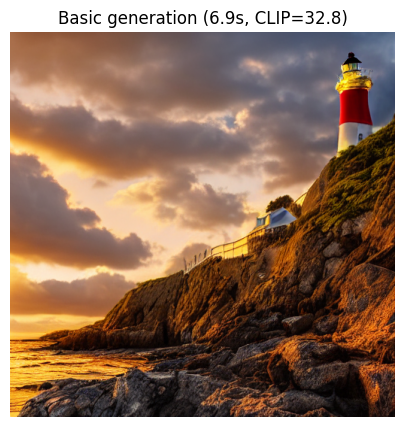

In [6]:
BASE_PROMPT = ("a lighthouse on a rocky cliff at sunset, dramatic clouds, golden hour lighting, "
               "highly detailed, 4k, photorealistic")

img, secs = generate(BASE_PROMPT, steps=30, guidance=7.5, seed=42)
img.save("outputs/01_basic.png")
plt.figure(figsize=(5, 5)); plt.imshow(img); plt.axis("off")
plt.title(f"Basic generation ({secs:.1f}s, CLIP={clip_score(img, BASE_PROMPT):.1f})")
plt.show()

## 5. Under the hood — manual denoising loop
Here we re-implement what `pipe(...)` does internally, step by step, using the individual components. This demonstrates: **prompt conditioning → random latent → iterative U-Net denoising with classifier-free guidance → VAE decoding.**

Token ids shape  : torch.Size([1, 77])
Text embedding   : (1, 77, 768) (batch, 77 tokens, 768 dims)
Initial latent   : (1, 4, 64, 64) -> 4 x 64 x 64 (vs 3 x 512 x 512 pixels)


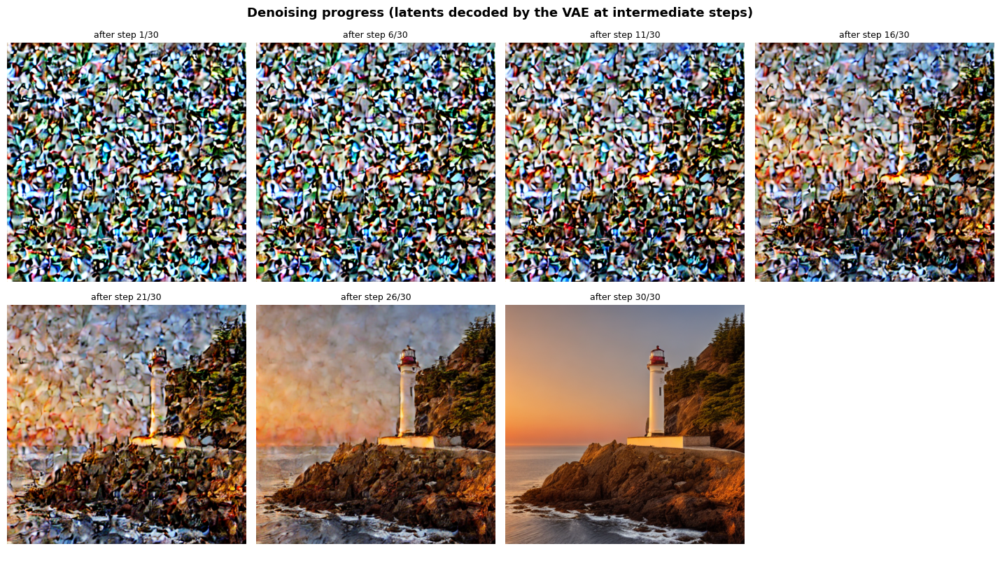

In [7]:
prompt = "a lighthouse on a rocky cliff at sunset, golden hour"
steps, guidance, seed = 30, 7.5, 42

# --- (1) Prompt conditioning: tokenizer + text encoder --------------------------------
tok = pipe.tokenizer
def encode(text):
    ids = tok(text, padding="max_length", max_length=tok.model_max_length,
              truncation=True, return_tensors="pt").input_ids.to(device)
    with torch.no_grad():
        return pipe.text_encoder(ids)[0]

cond_emb   = encode(prompt)      # embedding of the real prompt
uncond_emb = encode("")          # embedding of the empty prompt (for CFG)
text_emb   = torch.cat([uncond_emb, cond_emb])
print("Token ids shape  :", tok(prompt, padding='max_length', max_length=77, return_tensors='pt').input_ids.shape)
print("Text embedding   :", tuple(cond_emb.shape), "(batch, 77 tokens, 768 dims)")

# --- (2) Start from pure Gaussian noise in LATENT space -------------------------------
scheduler = DDIMScheduler.from_config(DEFAULT_SCHEDULER_CONFIG)
scheduler.set_timesteps(steps)
g = torch.Generator(device=device).manual_seed(seed)
latents = torch.randn((1, pipe.unet.config.in_channels, 64, 64), generator=g,
                      device=device, dtype=dtype) * scheduler.init_noise_sigma
print("Initial latent   :", tuple(latents.shape), "-> 4 x 64 x 64 (vs 3 x 512 x 512 pixels)")

def decode(lat):
    with torch.no_grad():
        im = pipe.vae.decode(lat / pipe.vae.config.scaling_factor).sample
    im = (im / 2 + 0.5).clamp(0, 1).cpu().permute(0, 2, 3, 1).float().numpy()[0]
    return Image.fromarray((im * 255).round().astype("uint8"))

# --- (3) Iterative denoising with the U-Net + classifier-free guidance ----------------
snapshots, snap_titles = [], []
snap_at = {0, 5, 10, 15, 20, 25, steps - 1}
for i, t in enumerate(scheduler.timesteps):
    lat_in = torch.cat([latents] * 2)                       # uncond + cond in one batch
    lat_in = scheduler.scale_model_input(lat_in, t)
    with torch.no_grad():
        noise_pred = pipe.unet(lat_in, t, encoder_hidden_states=text_emb).sample
    n_uncond, n_cond = noise_pred.chunk(2)
    noise_pred = n_uncond + guidance * (n_cond - n_uncond)   # classifier-free guidance
    latents = scheduler.step(noise_pred, t, latents).prev_sample   # scheduler update rule
    if i in snap_at:
        snapshots.append(decode(latents)); snap_titles.append(f"after step {i+1}/{steps}")

# --- (4) VAE decoder: latent -> image --------------------------------------------------
final = decode(latents)
final.save("outputs/02_manual_loop.png")
show_grid(snapshots, snap_titles, cols=4, suptitle="Denoising progress (latents decoded by the VAE at intermediate steps)",
          fname="02_denoising_progress")

**Observation:** the first snapshots look like coloured noise/blobs (global layout is decided in the early, high-noise steps); mid steps add shapes and structure; the final steps refine fine details and texture. This is exactly why very few steps give blurry or unfinished images.

## 6. Prompt engineering & negative prompts
### 6.1 Prompt variations (same seed, steps, guidance)
We start with a bare subject and progressively add *location, lighting, quality keywords* and *style* to see how control improves.

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

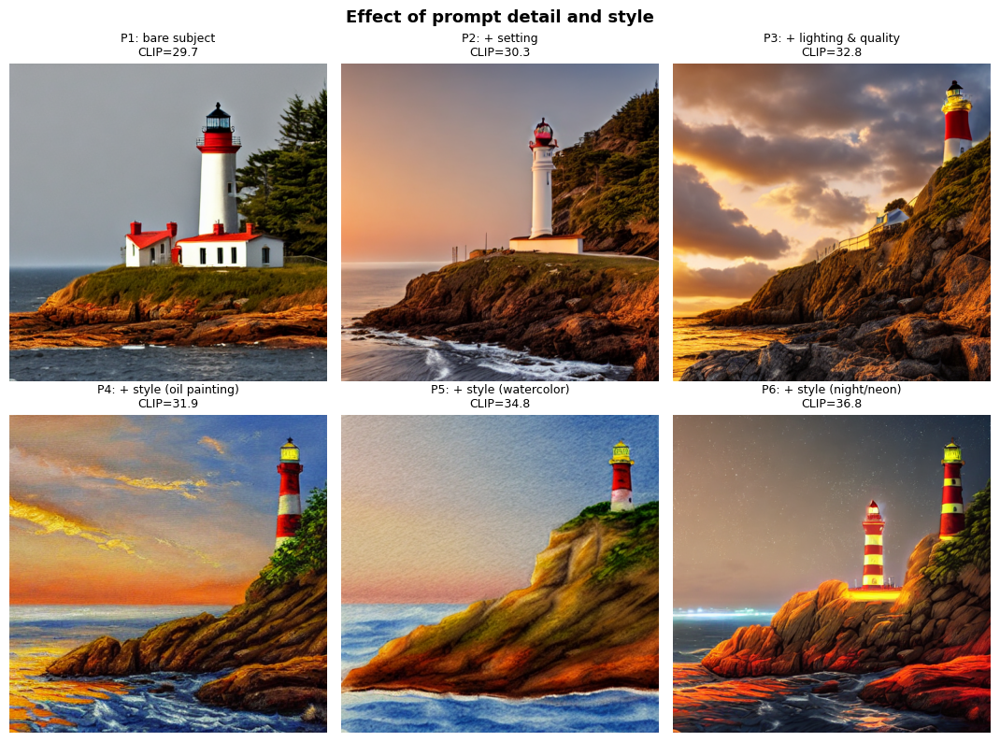

,prompt,text,clip_score,time_s
0,P1: bare subject,a lighthouse,29.67,6.4
1,P2: + setting,a lighthouse on a rocky cliff at sunset,30.26,6.3
2,P3: + lighting & quality,"a lighthouse on a rocky cliff at sunset, drama...",32.77,6.4
3,P4: + style (oil painting),"a lighthouse on a rocky cliff at sunset, drama...",31.85,6.5
4,P5: + style (watercolor),"a lighthouse on a rocky cliff at sunset, soft ...",34.76,6.5
5,P6: + style (night/neon),"a lighthouse on a rocky cliff at night, neon c...",36.78,6.6


Note: each CLIP score is measured against that image's OWN prompt, so scores are not comparable across prompts - judge prompt quality mainly by looking at the images.


In [8]:
prompt_variants = {
    "P1: bare subject":        "a lighthouse",
    "P2: + setting":           "a lighthouse on a rocky cliff at sunset",
    "P3: + lighting & quality": BASE_PROMPT,
    "P4: + style (oil painting)": "a lighthouse on a rocky cliff at sunset, dramatic clouds, oil painting, thick brush strokes, impressionism",
    "P5: + style (watercolor)":   "a lighthouse on a rocky cliff at sunset, soft pastel watercolor illustration, white paper texture",
    "P6: + style (night/neon)":    "a lighthouse on a rocky cliff at night, neon cyberpunk lighting, glowing sea, digital art, highly detailed",
}

imgs, titles, rows = [], [], []
for name, p in prompt_variants.items():
    im, s = generate(p, steps=30, guidance=7.5, seed=42)
    cs = clip_score(im, p)
    imgs.append(im); titles.append(f"{name}\nCLIP={cs:.1f}")
    rows.append({"prompt": name, "text": p, "clip_score": round(cs, 2), "time_s": round(s, 1)})
show_grid(imgs, titles, cols=3, suptitle="Effect of prompt detail and style", fname="03_prompt_variants")
prompt_df = pd.DataFrame(rows); display(prompt_df)
print("Note: each CLIP score is measured against that image's OWN prompt, so scores are not comparable "
      "across prompts - judge prompt quality mainly by looking at the images.")

### 6.2 Negative prompts
A negative prompt tells the model what to move *away from*. We compare the same prompt and seed **without** and **with** a negative prompt, for a subject where artefacts are common (faces/hands).

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

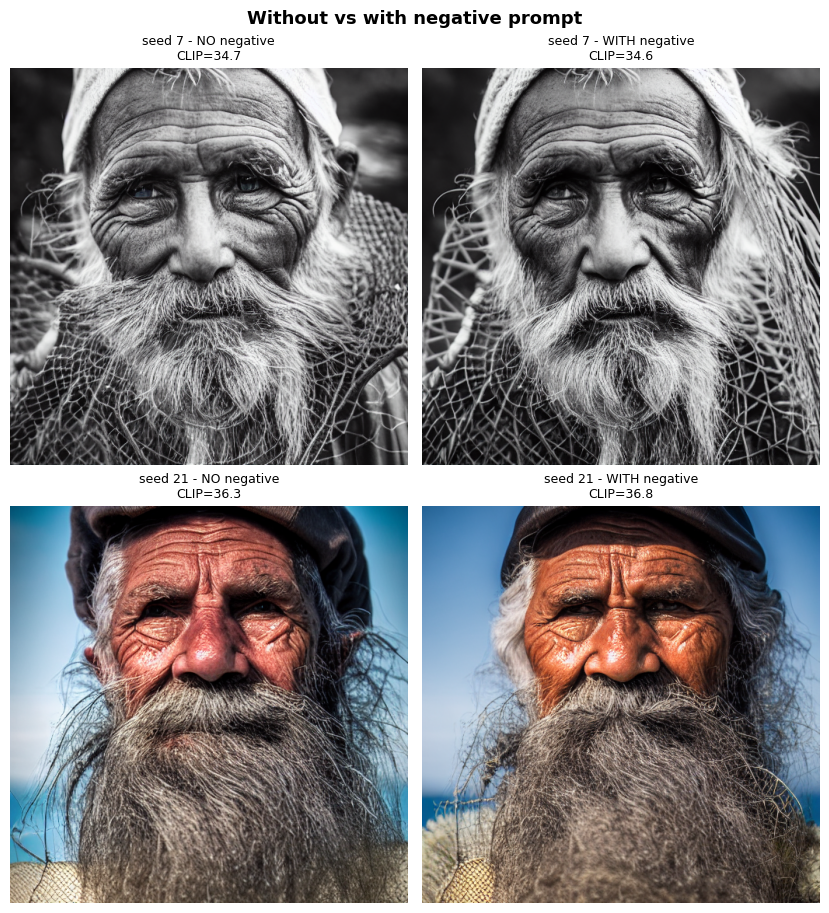

Negative prompt used: blurry, low quality, low resolution, deformed, bad anatomy, extra fingers, disfigured, watermark, text, cropped


In [9]:
neg_prompt = "blurry, low quality, low resolution, deformed, bad anatomy, extra fingers, disfigured, watermark, text, cropped"
subject = "portrait photo of an old fisherman holding a net, detailed face, natural light, 85mm lens"

imgs, titles = [], []
for sd in [7, 21]:
    a, _ = generate(subject, negative_prompt=None,       steps=30, guidance=7.5, seed=sd)
    b, _ = generate(subject, negative_prompt=neg_prompt, steps=30, guidance=7.5, seed=sd)
    imgs += [a, b]
    titles += [f"seed {sd} - NO negative\nCLIP={clip_score(a, subject):.1f}",
               f"seed {sd} - WITH negative\nCLIP={clip_score(b, subject):.1f}"]
show_grid(imgs, titles, cols=2, size=4.2, suptitle="Without vs with negative prompt", fname="04_negative_prompt")
print("Negative prompt used:", neg_prompt)

## 7. Effect of the number of inference steps
Everything fixed (prompt, seed 42, guidance 7.5, PNDM scheduler) — only `num_inference_steps` changes. We record **time** and **CLIP score**.

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

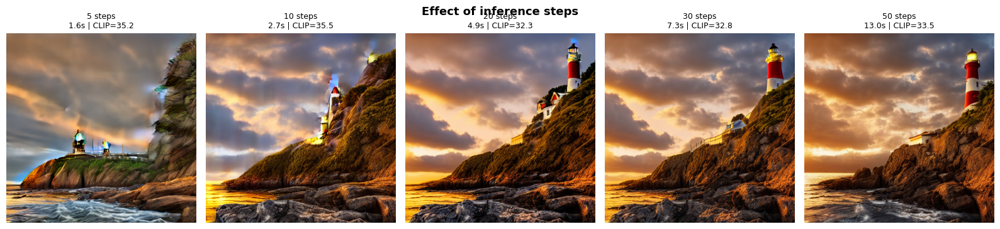

,steps,time_s,clip_score
0,5,1.60,35.17
1,10,2.71,35.52
2,20,4.93,32.32
3,30,7.29,32.77
4,50,12.99,33.52


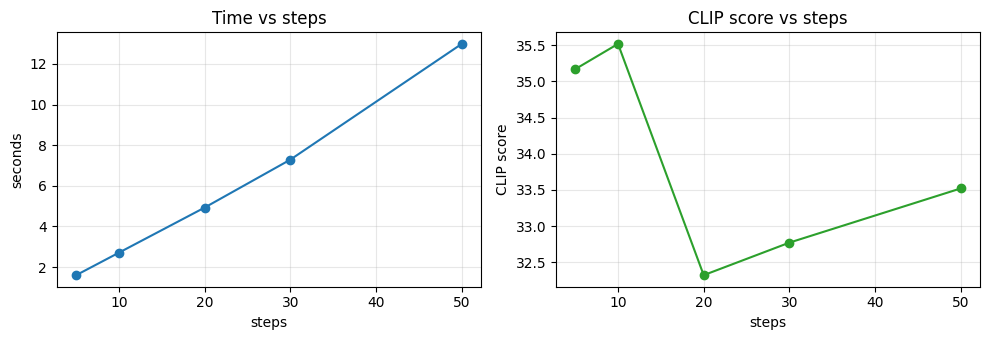

In [10]:
step_list = [5, 10, 20, 30, 50]
imgs, titles, rows = [], [], []
for st in step_list:
    im, s = generate(BASE_PROMPT, steps=st, guidance=7.5, seed=42)
    cs = clip_score(im, BASE_PROMPT)
    imgs.append(im); titles.append(f"{st} steps\n{s:.1f}s | CLIP={cs:.1f}")
    rows.append({"steps": st, "time_s": round(s, 2), "clip_score": round(cs, 2)})
show_grid(imgs, titles, cols=5, size=3.2, suptitle="Effect of inference steps", fname="05_steps")
steps_df = pd.DataFrame(rows); display(steps_df)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(steps_df.steps, steps_df.time_s, "o-"); ax[0].set(title="Time vs steps", xlabel="steps", ylabel="seconds"); ax[0].grid(alpha=.3)
ax[1].plot(steps_df.steps, steps_df.clip_score, "o-", color="tab:green"); ax[1].set(title="CLIP score vs steps", xlabel="steps", ylabel="CLIP score"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig("outputs/05_steps_plot.png", dpi=150); plt.show()

## 8. Effect of guidance scale (classifier-free guidance)
Everything fixed (prompt, seed 42, 30 steps, PNDM) — only `guidance_scale` changes.

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

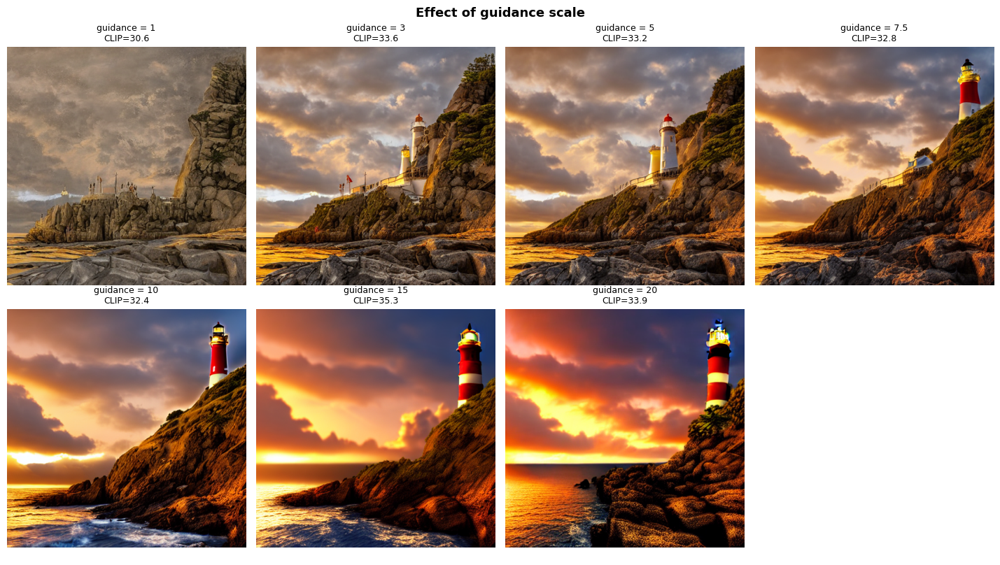

,guidance,clip_score,time_s
0,1.0,30.58,4.61
1,3.0,33.64,7.52
2,5.0,33.21,7.43
3,7.5,32.77,7.31
4,10.0,32.44,8.96
5,15.0,35.28,7.18
6,20.0,33.89,7.15


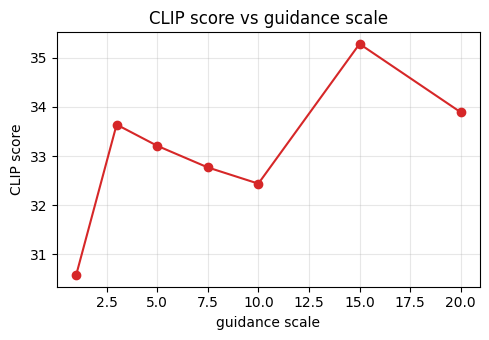

In [11]:
guid_list = [1, 3, 5, 7.5, 10, 15, 20]
imgs, titles, rows = [], [], []
for gs in guid_list:
    im, s = generate(BASE_PROMPT, steps=30, guidance=gs, seed=42)
    cs = clip_score(im, BASE_PROMPT)
    imgs.append(im); titles.append(f"guidance = {gs}\nCLIP={cs:.1f}")
    rows.append({"guidance": gs, "clip_score": round(cs, 2), "time_s": round(s, 2)})
show_grid(imgs, titles, cols=4, suptitle="Effect of guidance scale", fname="06_guidance")
guid_df = pd.DataFrame(rows); display(guid_df)

plt.figure(figsize=(5, 3.5))
plt.plot(guid_df.guidance, guid_df.clip_score, "o-", color="tab:red")
plt.title("CLIP score vs guidance scale"); plt.xlabel("guidance scale"); plt.ylabel("CLIP score"); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig("outputs/06_guidance_plot.png", dpi=150); plt.show()

## 9. Effect of the sampling method (scheduler)
Same prompt, seed, guidance (7.5); only the scheduler changes. We compare at **20 steps** (typical) and **8 steps** (low budget) to see which samplers converge faster.
As a reference for "converged" quality we also generate a 50-step DPM++ 2M image and report the **MSE** of each result against it (lower = closer to the converged image).

> **Caveat:** MSE is only a rough indicator. The reference comes from DPM++ 2M, so it slightly favours that family of solvers, and *ancestral* samplers (Euler Ancestral) add fresh random noise at every step, so they do not converge to the same image — a large MSE for them does not mean "worse quality". Always judge visually as well.

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

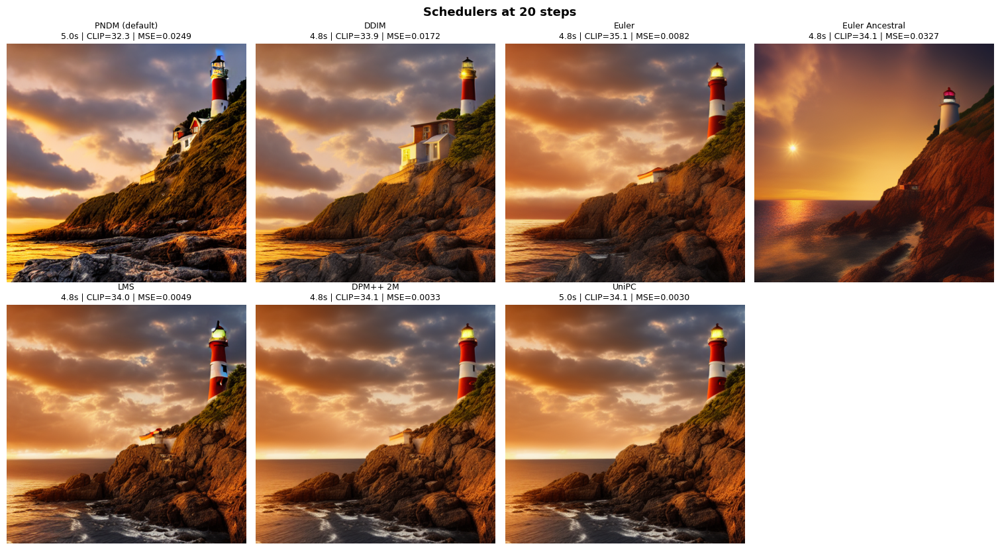

  0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

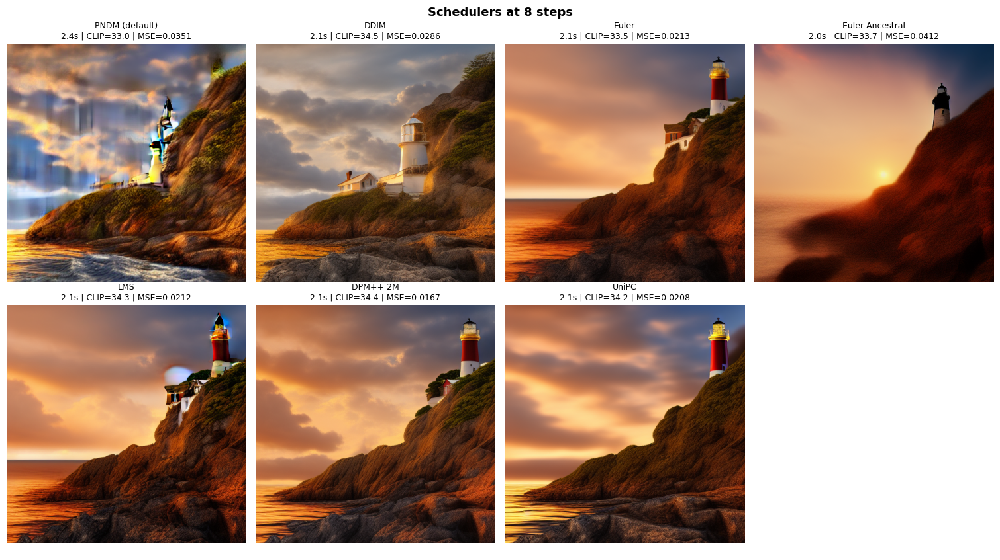

clip_score        mse_vs_ref         time_s      
steps                   8      20         8       20     8     20
scheduler                                                        
DDIM                 34.50  33.87     0.0286  0.0172   2.07  4.81
DPM++ 2M             34.42  34.10     0.0167  0.0033   2.09  4.82
Euler                33.50  35.14     0.0213  0.0082   2.06  4.77
Euler Ancestral      33.67  34.12     0.0412  0.0327   2.05  4.79
LMS                  34.34  33.97     0.0212  0.0049   2.07  4.82
PNDM (default)       33.03  32.32     0.0351  0.0249   2.36  4.99
UniPC                34.17  34.10     0.0208  0.0030   2.10  5.03

In [12]:
schedulers = {
    "PNDM (default)":      PNDMScheduler,
    "DDIM":                DDIMScheduler,
    "Euler":               EulerDiscreteScheduler,
    "Euler Ancestral":     EulerAncestralDiscreteScheduler,
    "LMS":                 LMSDiscreteScheduler,
    "DPM++ 2M":            DPMSolverMultistepScheduler,
    "UniPC":               UniPCMultistepScheduler,
}

ref_img, _ = generate(BASE_PROMPT, steps=50, guidance=7.5, seed=42, scheduler_cls=DPMSolverMultistepScheduler)
ref_arr = np.asarray(ref_img).astype(np.float32) / 255.0
def mse_to_ref(im):
    return float(np.mean((np.asarray(im).astype(np.float32) / 255.0 - ref_arr) ** 2))

all_rows = []
for st in [20, 8]:
    imgs, titles = [], []
    for name, cls in schedulers.items():
        im, s = generate(BASE_PROMPT, steps=st, guidance=7.5, seed=42, scheduler_cls=cls)
        cs, m = clip_score(im, BASE_PROMPT), mse_to_ref(im)
        imgs.append(im); titles.append(f"{name}\n{s:.1f}s | CLIP={cs:.1f} | MSE={m:.4f}")
        all_rows.append({"steps": st, "scheduler": name, "time_s": round(s, 2),
                         "clip_score": round(cs, 2), "mse_vs_ref": round(m, 4)})
    show_grid(imgs, titles, cols=4, size=3.8, suptitle=f"Schedulers at {st} steps", fname=f"07_schedulers_{st}steps")
    free_mem()

sched_df = pd.DataFrame(all_rows)
display(sched_df.pivot(index="scheduler", columns="steps", values=["clip_score", "mse_vs_ref", "time_s"]))

## 10. Combined analysis
### 10.1 Steps × guidance grid
Shows the interaction between the two parameters (DPM++ 2M scheduler so that low step counts are still meaningful).

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

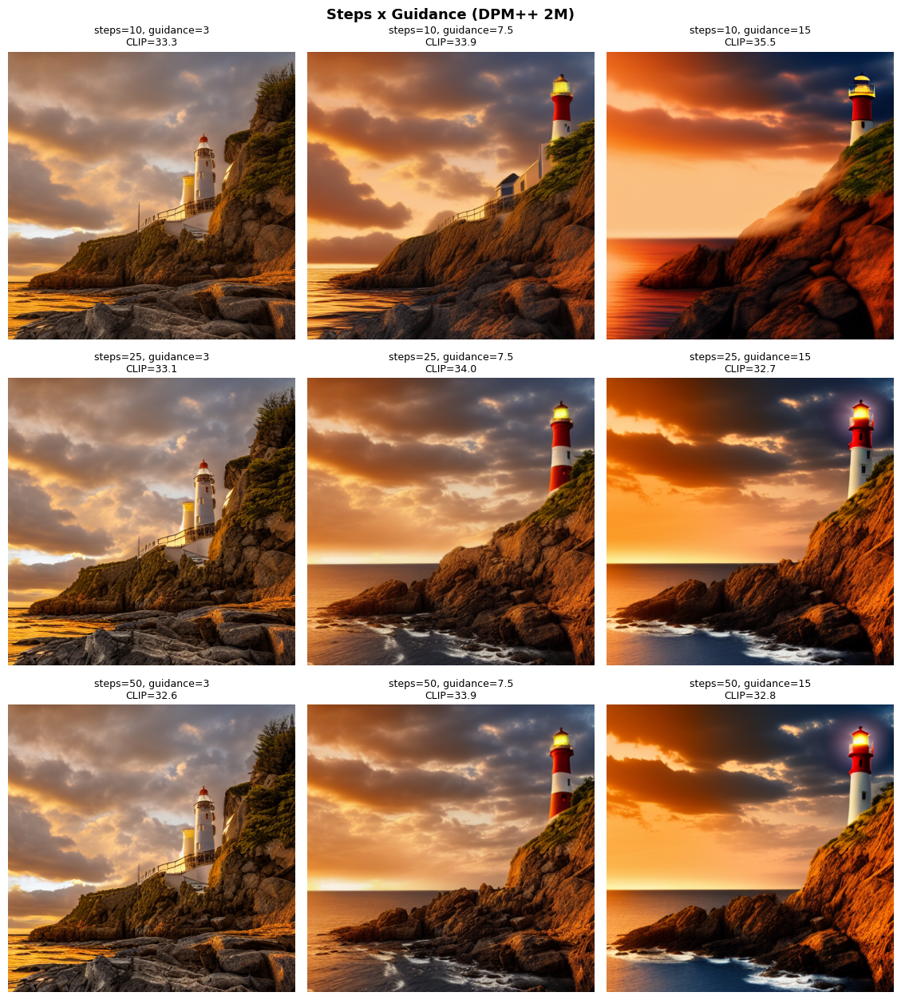

guidance,3.0,7.5,15.0
steps,,,
10,33.29,33.86,35.47
25,33.10,33.98,32.70
50,32.64,33.87,32.81


In [13]:
steps_g = [10, 25, 50]
guid_g = [3, 7.5, 15]
imgs, titles, rows = [], [], []
for st in steps_g:
    for gs in guid_g:
        im, s = generate(BASE_PROMPT, steps=st, guidance=gs, seed=42, scheduler_cls=DPMSolverMultistepScheduler)
        cs = clip_score(im, BASE_PROMPT)
        imgs.append(im); titles.append(f"steps={st}, guidance={gs}\nCLIP={cs:.1f}")
        rows.append({"steps": st, "guidance": gs, "clip_score": round(cs, 2)})
show_grid(imgs, titles, cols=3, size=3.8, suptitle="Steps x Guidance (DPM++ 2M)", fname="08_steps_x_guidance")
display(pd.DataFrame(rows).pivot(index="steps", columns="guidance", values="clip_score"))

### 10.2 Seed variation (same prompt & settings, different random starting noise)

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

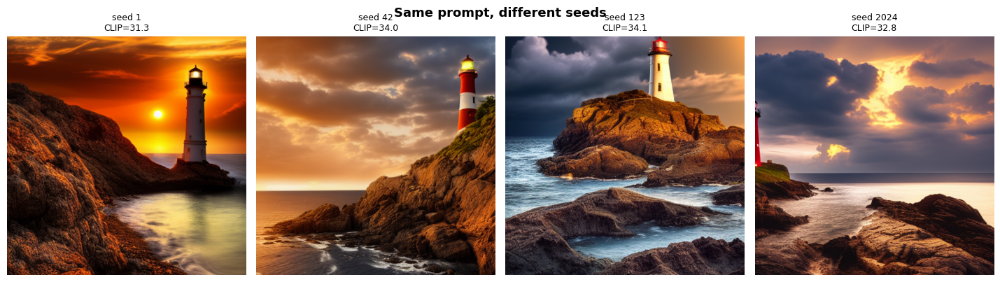

In [14]:
imgs, titles = [], []
for sd in [1, 42, 123, 2024]:
    im, _ = generate(BASE_PROMPT, steps=25, guidance=7.5, seed=sd, scheduler_cls=DPMSolverMultistepScheduler)
    imgs.append(im); titles.append(f"seed {sd}\nCLIP={clip_score(im, BASE_PROMPT):.1f}")
show_grid(imgs, titles, cols=4, suptitle="Same prompt, different seeds", fname="09_seeds")

## 11. Results, analysis & conclusion
The next cell computes the key findings **from your own result tables**. The written analysis after it describes the trends normally reported for SD v1.5 — read it next to your grids and edit any sentence that does not match what you see (numbers differ per run/GPU, and CLIP score is only a rough guide).

In [15]:
print("=== AUTO-SUMMARY FROM YOUR RESULTS ===\n")

# Steps
t5, t50 = steps_df.iloc[0], steps_df.iloc[-1]
print(f"[Steps]    time {t5.time_s:.1f}s at {int(t5.steps)} steps -> {t50.time_s:.1f}s at {int(t50.steps)} steps "
      f"(~{(t50.time_s - t5.time_s) / (t50.steps - t5.steps):.2f} s per extra step)")
best = steps_df.loc[steps_df.clip_score.idxmax()]
print(f"           highest CLIP score {best.clip_score} at {int(best.steps)} steps; "
      f"scores: " + ", ".join(f"{int(s)}:{c}" for s, c in zip(steps_df.steps, steps_df.clip_score)))

# Guidance
bg = guid_df.loc[guid_df.clip_score.idxmax()]
print(f"\n[Guidance] highest CLIP score {bg.clip_score} at guidance {bg.guidance}; "
      f"scores: " + ", ".join(f"{g}:{c}" for g, c in zip(guid_df.guidance, guid_df.clip_score)))
print("           (inspect the images: very high guidance often looks over-saturated even if CLIP stays high)")

# Schedulers
for st in [20, 8]:
    d = sched_df[sched_df.steps == st].sort_values("mse_vs_ref")
    print(f"\n[Schedulers @ {st} steps] closest to 50-step reference (lowest MSE): "
          + ", ".join(f"{r.scheduler} ({r.mse_vs_ref})" for r in d.itertuples()))
    print(f"           fastest: {d.loc[d.time_s.idxmin(), 'scheduler']} ({d.time_s.min()}s), "
          f"slowest: {d.loc[d.time_s.idxmax(), 'scheduler']} ({d.time_s.max()}s)")

=== AUTO-SUMMARY FROM YOUR RESULTS ===

[Steps]    time 1.6s at 5 steps -> 13.0s at 50 steps (~0.25 s per extra step)
           highest CLIP score 35.52 at 10 steps; scores: 5:35.17, 10:35.52, 20:32.32, 30:32.77, 50:33.52

[Guidance] highest CLIP score 35.28 at guidance 15.0; scores: 1.0:30.58, 3.0:33.64, 5.0:33.21, 7.5:32.77, 10.0:32.44, 15.0:35.28, 20.0:33.89
           (inspect the images: very high guidance often looks over-saturated even if CLIP stays high)

[Schedulers @ 20 steps] closest to 50-step reference (lowest MSE): UniPC (0.003), DPM++ 2M (0.0033), LMS (0.0049), Euler (0.0082), DDIM (0.0172), PNDM (default) (0.0249), Euler Ancestral (0.0327)
           fastest: Euler (4.77s), slowest: UniPC (5.03s)

[Schedulers @ 8 steps] closest to 50-step reference (lowest MSE): DPM++ 2M (0.0167), UniPC (0.0208), LMS (0.0212), Euler (0.0213), DDIM (0.0286), PNDM (default) (0.0351), Euler Ancestral (0.0412)
           fastest: Euler Ancestral (2.05s), slowest: PNDM (default) (2.36s)


### Written analysis

### 11.1 Prompt engineering
* A bare prompt (`"a lighthouse"`) gives a generic, uncontrolled image — composition, lighting and style are left to chance.
* Adding **setting → lighting → quality keywords → style** makes the output progressively more specific and controllable; style words (oil painting, watercolor, neon digital art) change the entire look while the subject remains.
* A **negative prompt** (blurry, deformed, extra fingers, watermark…) generally reduces artefacts such as blur, malformed anatomy and stray text/watermarks, giving cleaner and sharper results for the same seed. It does not guarantee perfection – some artefacts remain.

### 11.2 Number of inference steps
* **5 steps:** image is noisy/blurry and unfinished (with PNDM); overall layout is visible but details are missing.
* **10–20 steps:** recognisable scene, details improve quickly.
* **30–50 steps:** only small refinements; quality/CLIP score plateaus (**diminishing returns**).
* **Time grows roughly linearly** with steps (each step = one U-Net call on a batch of 2 because of classifier-free guidance). A good trade-off is ≈ 20–30 steps.
* Note: PNDM is the model's default scheduler, so 5 steps looks especially poor here; the same budget with DPM++ 2M/UniPC (Section 9) looks much better.

### 11.3 Guidance scale
* **1–3:** image is loosely related to the prompt, washed out / low contrast, "dreamy" — high diversity, low adherence.
* **5–10 (≈7.5):** best balance of prompt adherence, realism and detail.
* **15–20:** very strong adherence but over-saturated colours, harsh contrast, burnt textures and artefacts; diversity drops. CLIP score may rise or flatten while visual quality gets *worse* — CLIP score alone is not a quality measure.

### 11.4 Sampling methods (schedulers)
* At **20 steps** most modern samplers (Euler, DPM++ 2M, UniPC, DDIM) give good results with small stylistic differences.
* At **8 steps** the higher-order solvers (DPM++ 2M, UniPC) typically stay closest to the converged reference (lowest MSE) and look cleaner, while PNDM, LMS and DDIM often look blurrier or noisier at such a low budget — **confirm this against your MSE table and images**.
* **Euler Ancestral** injects fresh noise at each step, so it does not converge to a single image — results change with the number of steps, and its MSE vs the reference is not a fair quality measure.
* Time per step is almost the same for all samplers (the U-Net dominates the cost); the difference is *quality per step*.

### 11.5 Interaction & randomness
* Low steps cannot be rescued by high guidance, and high steps cannot rescue a bad guidance value — both matter.
* The **seed** (initial latent noise) changes the composition completely; to compare parameters fairly we must keep it fixed.

### 11.6 Conclusion
A pretrained latent diffusion model (CLIP text encoder + U-Net + scheduler + VAE) can generate high-quality images from text without any training. Output quality and control depend on (1) descriptive prompts with negative prompts, (2) a sufficient but not excessive number of steps (~20–30 with a modern scheduler), (3) a moderate guidance scale (~5–10) and (4) the choice of sampler (DPM++ 2M / UniPC give the best quality for the fewest steps). Recommended default: **DPM++ 2M, 25 steps, guidance 7.5, descriptive prompt + negative prompt.**

### 11.7 Limitations
Results are from one prompt and a few seeds; CLIP score only measures text–image similarity (not aesthetics); SD v1.5 is limited at 512×512 and struggles with hands, text and complex compositions.

In [16]:
# Save all result tables for the report
prompt_df.to_csv("outputs/table_prompts.csv", index=False)
steps_df.to_csv("outputs/table_steps.csv", index=False)
guid_df.to_csv("outputs/table_guidance.csv", index=False)
sched_df.to_csv("outputs/table_schedulers.csv", index=False)
print("Saved:", sorted(os.listdir("outputs")))

# (optional, Colab) download everything:
# !zip -qr outputs.zip outputs && echo zipped
# from google.colab import files; files.download("outputs.zip")

Saved: ['01_basic.png', '02_denoising_progress.png', '02_manual_loop.png', '03_prompt_variants.png', '04_negative_prompt.png', '05_steps.png', '05_steps_plot.png', '06_guidance.png', '06_guidance_plot.png', '07_schedulers_20steps.png', '07_schedulers_8steps.png', '08_steps_x_guidance.png', '09_seeds.png', 'table_guidance.csv', 'table_prompts.csv', 'table_schedulers.csv', 'table_steps.csv']
